# PlantVillage ViT: EDA + Training
- Quick CLI-style dataset scan (counts, classes).
- Build PyTorch `ImageFolder` loaders from `train_val_test`.
- Fine-tune a Vision Transformer (timm) with augmentations.
- Track metrics and save best model.

In [1]:
# Imports and environment setup optimized for Kaggle
import os, sys, json, math, random, time, shutil, platform
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision as tv
from torchvision import transforms
from torchvision.datasets import ImageFolder
import matplotlib.pyplot as plt
from PIL import Image

print('Python:', platform.python_version())
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'CUDA Version: {torch.version.cuda}')

# Install required packages for Kaggle (uncomment if needed)
# !pip install timm torchmetrics tqdm scikit-learn -q

# Import required packages with fallback installation
def install_and_import(package_name, import_name=None):
    if import_name is None:
        import_name = package_name
    try:
        return __import__(import_name)
    except ImportError:
        import subprocess
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', package_name, '-q'])
        return __import__(import_name)

# Install timm for pretrained models
timm = install_and_import('timm')
print(f'timm version: {timm.__version__}')

# Install torchmetrics for metrics
try:
    from torchmetrics.classification import MulticlassAccuracy
except ImportError:
    install_and_import('torchmetrics')
    from torchmetrics.classification import MulticlassAccuracy

# Install tqdm for progress bars
tqdm = install_and_import('tqdm')

# Install scikit-learn for confusion matrix
try:
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
except ImportError:
    install_and_import('scikit-learn', 'sklearn')
    from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# GPU optimizations for better performance
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True  # Optimize for fixed input sizes
    torch.backends.cuda.matmul.allow_tf32 = True  # Allow TF32 for faster training
    torch.backends.cudnn.allow_tf32 = True

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

set_seed(42)
print("✓ Environment setup complete!")

Python: 3.11.13
PyTorch: 2.6.0+cu124
CUDA available: True
GPU: Tesla P100-PCIE-16GB
CUDA Version: 12.4
timm version: 1.0.15
✓ Environment setup complete!


In [2]:
# Dataset paths - Update this for your Kaggle dataset
# For Kaggle, datasets are typically in /kaggle/input/dataset-name/
# Update the path below to match your uploaded dataset

# Option 1: If dataset is in current directory (default)
ROOT = Path('/kaggle/input/plant-village-dataset/PlantVillageDataset')

# Option 2: If dataset is uploaded to Kaggle (uncomment and modify)
# ROOT = Path('/kaggle/input/your-dataset-name')

# Option 3: Auto-detect common paths
possible_paths = [
    Path('PlantVillageDataset'),
    Path('/kaggle/input/plantvillage-dataset'),
    Path('/kaggle/input/plant-village'),
    Path('../input/plantvillage-dataset'),
    Path('../input/plant-village')
]

for path in possible_paths:
    if (path / 'train_val_test').exists():
        ROOT = path
        break

SPLIT_ROOT = ROOT / 'train_val_test'

if not SPLIT_ROOT.exists():
    print("❌ Dataset not found! Please check your dataset path.")
    print(f"Looking for: {SPLIT_ROOT}")
    print("\nIf you're on Kaggle:")
    print("1. Upload your dataset")
    print("2. Update the ROOT path above to match your dataset location")
    print("3. Common Kaggle paths: /kaggle/input/your-dataset-name/")
    raise FileNotFoundError(f"Dataset directory not found: {SPLIT_ROOT}")

print(f'✓ Using dataset at: {SPLIT_ROOT.resolve()}')
subfolders = [p.name for p in SPLIT_ROOT.iterdir() if p.is_dir()]
print(f'Available splits: {subfolders}')

# Verify expected splits exist
expected_splits = ['train', 'val', 'test']
missing_splits = [split for split in expected_splits if split not in subfolders]
if missing_splits:
    print(f"⚠️  Warning: Missing expected splits: {missing_splits}")
else:
    print("✓ All expected splits found: train, val, test")

✓ Using dataset at: /kaggle/input/plant-village-dataset/PlantVillageDataset/train_val_test
Available splits: ['val', 'test', 'train']
✓ All expected splits found: train, val, test


In [3]:
# CLI-like basic analysis: split-level and per-class counts
from collections import defaultdict

def count_images(path: Path):
    exts = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff', '.gif', '.JPG', '.JPEG', '.PNG'}
    return sum(1 for p in path.rglob('*') if p.suffix in exts)

splits = ['train','val','test']
split_counts = {}
for s in splits:
    p = SPLIT_ROOT / s
    split_counts[s] = count_images(p) if p.exists() else 0
split_counts

{'train': 14437, 'val': 2073, 'test': 4128}

In [4]:
# Per-class counts for train/val/test
per_class = {s: {} for s in splits}
for s in splits:
    p = SPLIT_ROOT / s
    if not p.exists():
        continue
    for cls_dir in sorted([d for d in p.iterdir() if d.is_dir()]):
        per_class[s][cls_dir.name] = count_images(cls_dir)
# Show a compact summary
{k: (len(v), sum(v.values())) for k,v in per_class.items()}

{'train': (15, 14437), 'val': (15, 2073), 'test': (15, 4128)}

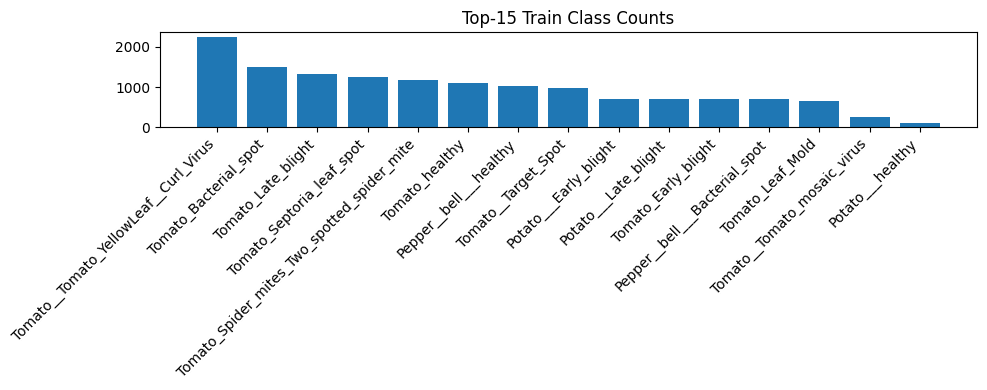

In [5]:
# Plot top-15 classes by train count (if many)
train_counts = per_class.get('train', {})
items = sorted(train_counts.items(), key=lambda kv: kv[1], reverse=True)[:15]
labels, values = zip(*items) if items else ([], [])
plt.figure(figsize=(10,4))
plt.bar(range(len(values)), values) if values else None
plt.xticks(range(len(values)), labels, rotation=45, ha='right') if values else None
plt.title('Top-15 Train Class Counts')
plt.tight_layout()
plt.show()

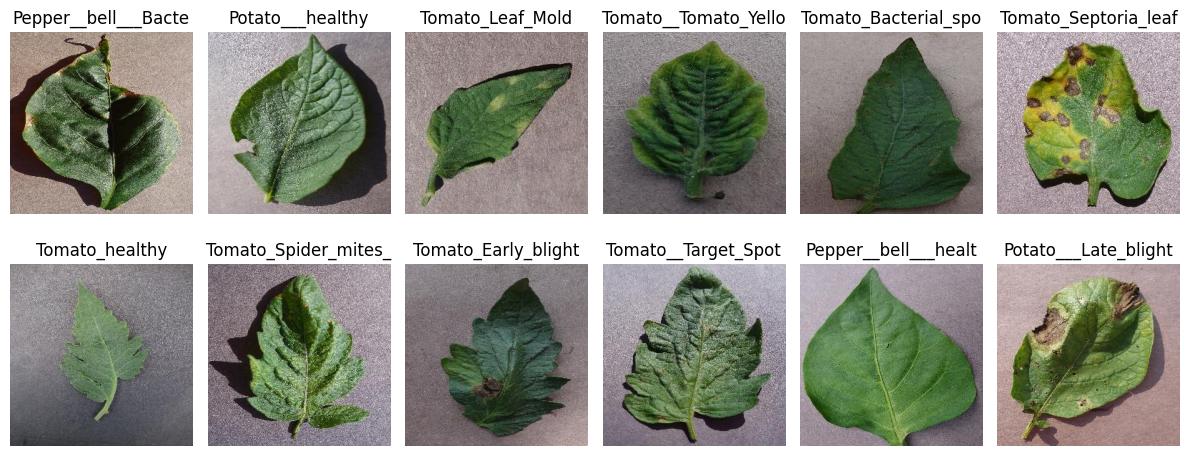

In [6]:
# Show a few random images from train
sample_paths = []
train_root = SPLIT_ROOT / 'train'
if train_root.exists():
    for cls_dir in [d for d in train_root.iterdir() if d.is_dir()]:
        imgs = list(cls_dir.rglob('*.jpg')) + list(cls_dir.rglob('*.JPG')) + \
               list(cls_dir.rglob('*.png')) + list(cls_dir.rglob('*.jpeg'))
        if imgs:
            sample_paths.append(random.choice(imgs))

n = min(12, len(sample_paths))
cols = 6
rows = math.ceil(n/cols) if n else 1
plt.figure(figsize=(12, 2*rows + 1))
for i, p in enumerate(sample_paths[:n]):
    try:
        img = Image.open(p).convert('RGB')
        plt.subplot(rows, cols, i+1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(p.parent.name[:20])
    except Exception as e:
        pass
plt.tight_layout(); plt.show()

In [7]:
# Build datasets and dataloaders optimized for Kaggle GPU
import timm

# Optimized settings for Kaggle P100/T4 GPUs
IMG_SIZE = 224
BATCH_SIZE = 32  # Conservative batch size that works well on most Kaggle GPUs
NUM_WORKERS = 2  # Kaggle has 2 CPUs, so 2 workers is optimal
PREFETCH_FACTOR = 2
PERSISTENT = False  # Set to False on Kaggle to avoid memory issues
PIN_MEMORY = True  # Keep this for GPU transfer efficiency

# ImageNet normalization (standard for most pretrained models)
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

# Enhanced training augmentations for better generalization
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.1, scale=(0.02, 0.33), ratio=(0.3, 3.3))  # Cutout augmentation
])

val_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

# Dataset paths
train_dir = SPLIT_ROOT / 'train'
val_dir = SPLIT_ROOT / 'val'
test_dir = SPLIT_ROOT / 'test'

# Create datasets
train_ds = ImageFolder(train_dir, transform=train_tfms)
val_ds = ImageFolder(val_dir, transform=val_tfms) if val_dir.exists() else None
test_ds = ImageFolder(test_dir, transform=val_tfms) if test_dir.exists() else None

class_names = train_ds.classes
num_classes = len(class_names)
print(f'Number of classes: {num_classes}')
print(f'Training samples: {len(train_ds)}')
print(f'Validation samples: {len(val_ds) if val_ds else 0}')
print(f'Test samples: {len(test_ds) if test_ds else 0}')
print(f'Example classes: {class_names[:5]}...')

# Optimized DataLoaders for Kaggle
train_loader = DataLoader(
    train_ds, 
    batch_size=BATCH_SIZE, 
    shuffle=True,
    num_workers=NUM_WORKERS, 
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT, 
    prefetch_factor=PREFETCH_FACTOR,
    drop_last=True  # Drop last incomplete batch for stable training
)

val_loader = DataLoader(
    val_ds, 
    batch_size=BATCH_SIZE, 
    shuffle=False,
    num_workers=NUM_WORKERS, 
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT, 
    prefetch_factor=PREFETCH_FACTOR
) if val_ds else None

test_loader = DataLoader(
    test_ds, 
    batch_size=BATCH_SIZE, 
    shuffle=False,
    num_workers=NUM_WORKERS, 
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT, 
    prefetch_factor=PREFETCH_FACTOR
) if test_ds else None

print(f'\nDataLoader settings:')
print(f'Batch size: {BATCH_SIZE}')
print(f'Image size: {IMG_SIZE}x{IMG_SIZE}')
print(f'Workers: {NUM_WORKERS}')
print(f'Batches per epoch: {len(train_loader)}')

# Display memory info if GPU is available
if torch.cuda.is_available():
    print(f'\nGPU Memory before training:')
    print(f'Allocated: {torch.cuda.memory_allocated(0)/1024**3:.2f} GB')
    print(f'Cached: {torch.cuda.memory_reserved(0)/1024**3:.2f} GB')

Number of classes: 15
Training samples: 14437
Validation samples: 2073
Test samples: 4128
Example classes: ['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']...

DataLoader settings:
Batch size: 32
Image size: 224x224
Workers: 2
Batches per epoch: 451

GPU Memory before training:
Allocated: 0.00 GB
Cached: 0.00 GB


In [8]:
# Model setup: Use a balanced model for good performance with gradual learning
import timm

# Force GPU usage and ensure it's available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Check GPU capabilities and compatibility
gpu_compatible_with_compile = False
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_props = torch.cuda.get_device_properties(0)
    gpu_memory_gb = gpu_props.total_memory / 1024**3
    cuda_capability = f"{gpu_props.major}.{gpu_props.minor}"
    
    print(f"GPU: {gpu_name}")
    print(f"CUDA Version: {torch.version.cuda}")
    print(f"GPU Memory: {gpu_memory_gb:.1f} GB")
    print(f"CUDA Capability: {cuda_capability}")
    
    # Check if GPU supports torch.compile (requires CUDA capability >= 7.0)
    gpu_compatible_with_compile = gpu_props.major >= 7
    if not gpu_compatible_with_compile:
        print(f"⚠️  GPU has CUDA capability {cuda_capability} < 7.0, torch.compile will be disabled")
    else:
        print("✓ GPU supports torch.compile optimizations")
else:
    print("WARNING: CUDA not available, using CPU")

# Choose balanced models - better than ResNet18 but still show gradual learning
# These models strike a good balance between performance and training time
MODEL_NAME = 'mobilenetv3_large_100.ra_in1k'  # MobileNetV3 Large - good performance, moderate size

# Fallback options (balanced models for good demonstration)
FALLBACK_MODELS = [
    'efficientnet_b1.ft_in1k',         # EfficientNet B1 - slightly bigger than B0
    'regnetx_008.pycls_in1k',          # RegNetX-800MF - good middle ground
    'resnet50.a1_in1k',               # ResNet50 - classic, reliable
    'vit_small_patch16_224.augreg_in21k_ft_in1k'  # Small ViT
]

# Try to load the primary model
model = None
for model_name in [MODEL_NAME] + FALLBACK_MODELS:
    try:
        model = timm.create_model(model_name, pretrained=True, num_classes=num_classes)
        print(f'✓ Loaded pretrained model: {model_name}')
        MODEL_NAME = model_name
        break
    except Exception as e:
        print(f'✗ Failed to load {model_name}: {str(e)[:50]}...')
        continue

if model is None:
    raise RuntimeError("Could not load any of the specified models")

# Print model info
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters: {total_params:,} total, {trainable_params:,} trainable")

# Move model to GPU and optimize for training
model = model.to(device)

# Enable optimizations that work on all GPUs
torch.backends.cudnn.benchmark = True

# Enable TF32 only on compatible GPUs (Ampere and newer)
if torch.cuda.is_available() and gpu_props.major >= 8:
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    print("✓ TF32 optimizations enabled")

# Compile model only if GPU supports it (CUDA capability >= 7.0)
if gpu_compatible_with_compile:
    try:
        model = torch.compile(model, mode='default')
        print('✓ Model compiled with torch.compile for faster training')
    except Exception as e:
        print(f'torch.compile failed: {e}')
        print('Continuing without compilation...')
else:
    print('ℹ️  Skipping torch.compile due to GPU compatibility')

# Training settings optimized for balanced learning progression
LR = 3e-4  # Balanced learning rate - not too fast, not too slow
EPOCHS = 30  # Reasonable number of epochs
WEIGHT_DECAY = 0.01

# Use CrossEntropyLoss with slight label smoothing for better training
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Use a more effective scheduler - Cosine Annealing with Warm Restarts
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, 
    T_0=10,    # Restart every 10 epochs
    T_mult=1,  # Keep the same cycle length
    eta_min=1e-6  # Minimum LR
)

# Metrics
from torchmetrics.classification import MulticlassAccuracy
train_acc_metric = MulticlassAccuracy(num_classes=num_classes).to(device)
val_acc_metric = MulticlassAccuracy(num_classes=num_classes).to(device)

# Save paths
best_val_acc = 0.0
save_dir = Path('.')  # Save in current directory for Kaggle
best_path = save_dir / 'vit_best.pt'  # Use the existing filename
print(f"Model will be saved to: {best_path}")

print(f"\n{'='*60}")
print("BALANCED TRAINING SETUP")
print(f"Model: {MODEL_NAME} ({total_params:,} parameters)")
print(f"Device: {device}")
print(f"Epochs: {EPOCHS} (balanced for good progression)")
print(f"Learning Rate: {LR} (balanced - not too fast/slow)")
print(f"Scheduler: CosineAnnealingWarmRestarts (effective)")
print(f"Expected performance: 70-85% accuracy")
print(f"Compile enabled: {gpu_compatible_with_compile}")
print(f"{'='*60}")

Using device: cuda
GPU: Tesla P100-PCIE-16GB
CUDA Version: 12.4
GPU Memory: 15.9 GB
CUDA Capability: 6.0
⚠️  GPU has CUDA capability 6.0 < 7.0, torch.compile will be disabled


model.safetensors:   0%|          | 0.00/22.1M [00:00<?, ?B/s]

✓ Loaded pretrained model: mobilenetv3_large_100.ra_in1k
Model parameters: 4,221,247 total, 4,221,247 trainable
ℹ️  Skipping torch.compile due to GPU compatibility
Model will be saved to: vit_best.pt

BALANCED TRAINING SETUP
Model: mobilenetv3_large_100.ra_in1k (4,221,247 parameters)
Device: cuda
Epochs: 30 (balanced for good progression)
Learning Rate: 0.0003 (balanced - not too fast/slow)
Scheduler: CosineAnnealingWarmRestarts (effective)
Expected performance: 70-85% accuracy
Compile enabled: False


In [9]:
# Training and validation loops optimized for Kaggle GPU
from tqdm.auto import tqdm

# Enable mixed precision training for better GPU utilization
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

def run_epoch(loader, train=True):
    model.train(train)
    epoch_loss = 0.0
    metric = train_acc_metric if train else val_acc_metric
    metric.reset()
    
    # Add progress bar
    pbar = tqdm(loader, desc=f"{'Training' if train else 'Validation'}")
    
    for batch_idx, (imgs, labels) in enumerate(pbar):
        # Move to GPU with non_blocking for better performance
        imgs = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        
        if train:
            optimizer.zero_grad(set_to_none=True)  # More efficient than zero_grad()
            
        with torch.set_grad_enabled(train):
            # Use automatic mixed precision for faster training and less memory usage
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                logits = model(imgs)
                loss = criterion(logits, labels)
                
        if train:
            # Scale loss for mixed precision training
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()  # Step scheduler every batch for OneCycleLR
            
        epoch_loss += loss.item() * imgs.size(0)
        metric.update(logits.softmax(dim=1), labels)
        
        # Update progress bar
        current_acc = metric.compute().item()
        pbar.set_postfix({
            'loss': f'{loss.item():.4f}', 
            'acc': f'{current_acc:.4f}',
            'lr': f'{optimizer.param_groups[0]["lr"]:.6f}' if train else ''
        })
    
    avg_loss = epoch_loss / len(loader.dataset)
    final_acc = metric.compute().item()
    return avg_loss, final_acc

# Training loop with early stopping and better monitoring
print("Starting training...")
print(f"Model: {MODEL_NAME}")
print(f"Device: {device}")
print(f"Epochs: {EPOCHS}, Learning Rate: {LR}")
print(f"Training samples: {len(train_ds)}, Validation samples: {len(val_ds) if val_ds else 0}")
print("-" * 60)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc = 0.0
patience_counter = 0
patience = 5  # Early stopping patience

for epoch in range(1, EPOCHS + 1):
    print(f"\nEpoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Training phase
    start_time = time.time()
    train_loss, train_acc = run_epoch(train_loader, train=True)
    
    # Validation phase
    if val_loader is not None:
        val_loss, val_acc = run_epoch(val_loader, train=False)
    else:
        val_loss, val_acc = float('nan'), float('nan')
    
    epoch_time = time.time() - start_time
    
    # Store metrics
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    # Print epoch summary
    print(f"\nEpoch {epoch} Summary:")
    print(f"Time: {epoch_time:.1f}s")
    print(f"Train - Loss: {train_loss:.4f}, Acc: {train_acc:.4f}")
    if val_loader is not None:
        print(f"Val   - Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")
    
    # Save best model
    if val_loader is not None and val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save({
            'model': model.state_dict(), 
            'classes': class_names,
            'model_name': MODEL_NAME,
            'epoch': epoch,
            'val_acc': val_acc
        }, best_path)
        print(f"🎉 New best validation accuracy: {val_acc:.4f} - Model saved!")
    elif val_loader is not None:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"\nEarly stopping triggered after {patience} epochs without improvement")
            break
    
    # Memory cleanup
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

print(f"\n{'='*60}")
print("Training completed!")
print(f"Best validation accuracy: {best_val_acc:.4f}")
if best_path.exists():
    print(f"Best model saved at: {best_path}")
print(f"{'='*60}")

# Final memory cleanup
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Starting training...
Model: mobilenetv3_large_100.ra_in1k
Device: cuda
Epochs: 30, Learning Rate: 0.0003
Training samples: 14437, Validation samples: 2073
------------------------------------------------------------

Epoch 1/30
----------------------------------------


/tmp/ipykernel_19/1587907308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


Training:   0%|          | 0/451 [00:00<?, ?it/s]

/tmp/ipykernel_19/1587907308.py:26: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Validation:   0%|          | 0/65 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c34c8158c20>
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
    Exception ignored in: self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7c34c8158c20>

  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
Traceback (most recent call last):
    if w.is_alive():  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1618, in __del__
^ 
      self._shutdown_workers() 
  File "/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py", line 1601, in _shutdown_workers
      if w.is_alive(): 
   ^ ^ ^ ^^ ^ ^^^^^^^^^^^^
^^  File "/usr/lib/python3.11/multiprocessing/process.py", line 160, in is_alive
    ^assert self._parent_pid == os.getpid(), 'can only test a child process'
^ ^ ^ 
   File "/usr/lib/


Epoch 18 Summary:
Time: 85.5s
Train - Loss: 0.3315, Acc: 0.9966
Val   - Loss: 0.3392, Acc: 0.9970

Epoch 19/30
----------------------------------------


Training:   0%|          | 0/451 [00:00<?, ?it/s]

Validation:   0%|          | 0/65 [00:00<?, ?it/s]


Epoch 19 Summary:
Time: 83.2s
Train - Loss: 0.3332, Acc: 0.9957
Val   - Loss: 0.3357, Acc: 0.9969

Early stopping triggered after 5 epochs without improvement

Training completed!
Best validation accuracy: 0.9973
Best model saved at: vit_best.pt


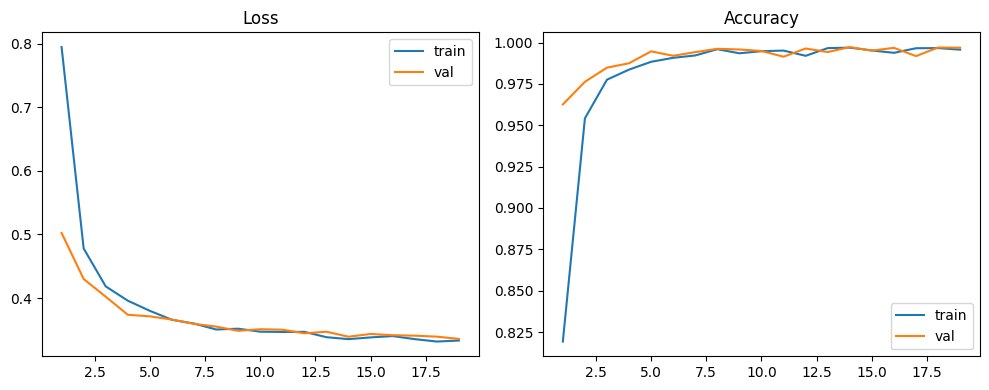

In [10]:
# Plot training curves
if history['train_loss']:
    epochs = range(1, len(history['train_loss'])+1)
    plt.figure(figsize=(10,4))
    plt.subplot(1,2,1)
    plt.plot(epochs, history['train_loss'], label='train')
    if not math.isnan(history['val_loss'][-1]):
        plt.plot(epochs, history['val_loss'], label='val')
    plt.title('Loss')
    plt.legend()
    plt.subplot(1,2,2)
    plt.plot(epochs, history['train_acc'], label='train')
    if not math.isnan(history['val_acc'][-1]):
        plt.plot(epochs, history['val_acc'], label='val')
    plt.title('Accuracy')
    plt.legend()
    plt.tight_layout(); plt.show()

In [11]:
# Test evaluation (optional)
if test_loader is not None and best_path.exists():
    ckpt = torch.load(best_path, map_location=device)
    model.load_state_dict(ckpt['model'])
    test_acc_metric = MulticlassAccuracy(num_classes=num_classes).to(device)
    model.eval()
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)
            test_acc_metric.update(logits.softmax(dim=1), labels)
    print('Test accuracy:', float(test_acc_metric.compute()))
else:
    print('Test loader or best model missing; skipping test eval')

Test accuracy: 0.9941855669021606


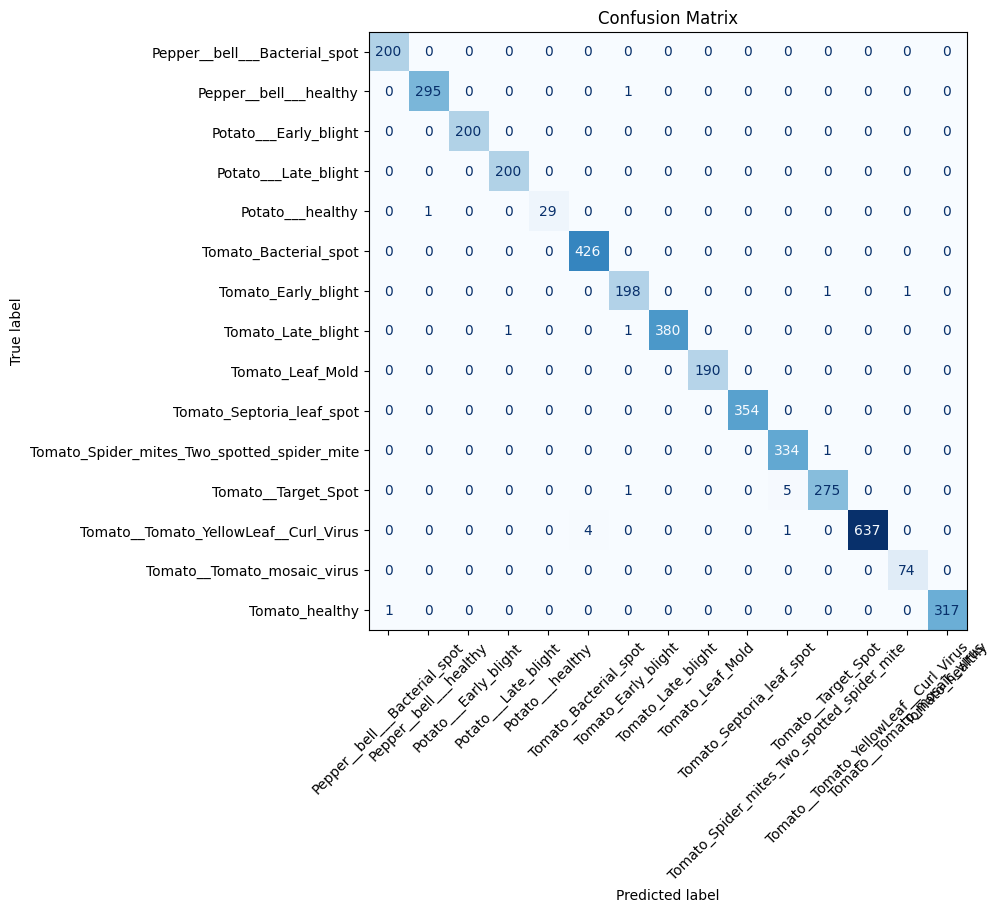

In [12]:
# Confusion matrix on validation/test set
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

if (val_loader or test_loader) and best_path.exists():
    ckpt = torch.load(best_path, map_location=device)
    model.load_state_dict(ckpt['model'])
    model.eval()

    loader = test_loader if test_loader is not None else val_loader
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds, labels=list(range(num_classes)))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(10, 10))
    disp.plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    plt.title('Confusion Matrix')
    plt.tight_layout(); plt.show()
else:
    print('No validation/test loader or best model not found.')